# Microsoft 3B — Milestone 1
## Final Exploratory Data Analysis: GitHub Repository Trust Signals

This notebook analyzes the consolidated 3A + 3B repository dataset using the final repository feature and label files. It examines data quality, label balance, feature completeness, Good versus Uncertain repositories, feature relationships, and preliminary individual-signal AUC.

**Interpretation note:** `good` is the known-good comparison class. `uncertain` is not a verified malicious or definitively bad class. The results here are exploratory and are intended to inform the final model and scoring tool.


## 1. Load the final datasets

The two files are joined using the shared `repo` identifier.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score
from IPython.display import display

sns.set_theme(style="whitegrid")

FEATURES_URL = "https://raw.githubusercontent.com/Break-Through-Tech/Microsoft-3B-github-repo-trust-signals/main/data/repo_featuresFINAL.csv"
LABELS_URL = "https://raw.githubusercontent.com/Break-Through-Tech/Microsoft-3B-github-repo-trust-signals/main/data/repo_labels_final.csv"

features = pd.read_csv(FEATURES_URL)
labels = pd.read_csv(LABELS_URL)

df = labels.merge(features, on="repo", how="outer", indicator=True)

print("Features shape:", features.shape)
print("Labels shape:", labels.shape)
print("Merged shape:", df.shape)
print("\nMerge status:")
print(df["_merge"].value_counts())
display(df.head())


Features shape: (240, 13)
Labels shape: (240, 9)
Merged shape: (240, 22)

Merge status:
_merge
both          240
left_only       0
right_only      0
Name: count, dtype: int64


,repo,label,label_reason,added_by,source,counterexample_type,last_commit,review_status,notes,days_since_last_commit,...,contributor_count,stars_to_forks,forks_checked,active_fork_ratio,merged_pr_count,archived,has_license,repo_age_days,error,_merge
0,666ghj/BettaFish,uncertain,uncertain,3a+3b,original_team_list,other,2026-10-02,auto_checked,NaN,40,...,41.0,5.59,100,0.01,125.0,0,1,862,NaN,both
1,666ghj/MiroFish,uncertain,uncertain,3b,original_team_list,other,2026-10-02,auto_checked,NaN,40,...,15.0,6.60,100,0.00,29.0,0,1,349,NaN,both
2,Azure/azure-cli,good,verified baseline,3a+3b,original_team_list,none,NaN,team_verified,From the verified team baseline list. Not indi...,0,...,416.0,1.32,100,0.14,12517.0,0,1,3932,NaN,both
3,Azure/azure-functions-host,good,verified baseline,3a+3b,original_team_list,none,NaN,team_verified,From the verified team baseline list. Not indi...,5,...,134.0,4.16,100,0.15,4389.0,0,1,4073,NaN,both
4,Azure/azure-sdk-for-js,good,verified baseline,3a+3b,original_team_list,none,NaN,team_verified,From the verified team baseline list. Not indi...,0,...,400.0,1.62,100,0.12,20631.0,0,1,3303,NaN,both


## 2. Validate the consolidated dataset

These checks identify duplicate repository keys, missing labels, unexpected labels, and rows that did not match between the two final files.


In [2]:
print("Duplicate repositories in features:", features["repo"].duplicated().sum())
print("Duplicate repositories in labels:", labels["repo"].duplicated().sum())
print("Missing labels:", df["label"].isna().sum())
print("Labels:")
print(df["label"].value_counts(dropna=False))

expected_labels = {"good", "uncertain"}
unexpected = sorted(set(df["label"].dropna()) - expected_labels)
print("Unexpected labels:", unexpected)


Duplicate repositories in features: 0
Duplicate repositories in labels: 0
Missing labels: 0
Labels:
label
good         142
uncertain     98
Name: count, dtype: int64
Unexpected labels: []


## 3. Label composition

The dataset contains a known-good comparison group and an uncertain comparison group.


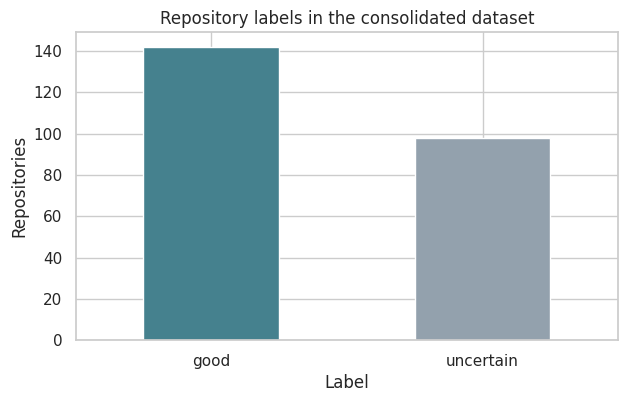

In [3]:
label_counts = df["label"].value_counts().reindex(["good", "uncertain"]).dropna()
ax = label_counts.plot(kind="bar", color=["#45818e", "#93a1ad"], figsize=(7, 4))
ax.set_title("Repository labels in the consolidated dataset")
ax.set_xlabel("Label")
ax.set_ylabel("Repositories")
plt.xticks(rotation=0)
plt.show()


### Figure takeaway

The consolidated dataset contains **142 known-good repositories** and **98 uncertain repositories**. The uncertain group is an experimental comparison group; it is **not** a confirmed malicious or definitively bad class.

## 4. Feature completeness

The `error` column records collection issues and is not a trust signal. It is excluded from the feature analysis. A blank value can represent an unavailable measurement, such as a repository with no releases.


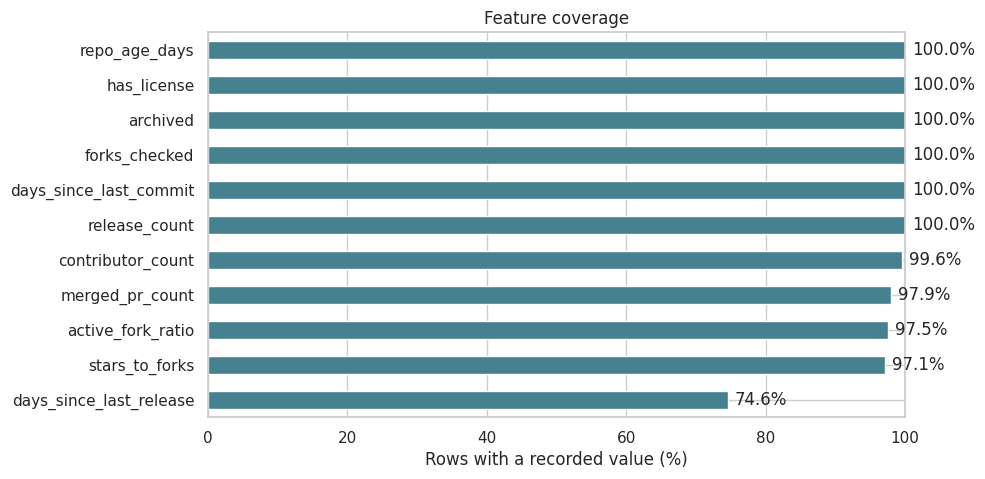

,missing_values,coverage_percent
days_since_last_release,61,74.6
stars_to_forks,7,97.1
active_fork_ratio,6,97.5
merged_pr_count,5,97.9
contributor_count,1,99.6
release_count,0,100.0
days_since_last_commit,0,100.0
forks_checked,0,100.0
archived,0,100.0
has_license,0,100.0


In [4]:
feature_columns = [
    "days_since_last_commit", "release_count", "days_since_last_release",
    "contributor_count", "stars_to_forks", "forks_checked",
    "active_fork_ratio", "merged_pr_count", "archived", "has_license",
    "repo_age_days"
]

missing = df[feature_columns].isna().sum().sort_values(ascending=False)
coverage = (1 - missing / len(df)).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(9, 5))
coverage.mul(100).plot(kind="barh", ax=ax, color="#45818e")
ax.set_title("Feature coverage")
ax.set_xlabel("Rows with a recorded value (%)")
ax.set_xlim(0, 100)
for i, value in enumerate(coverage.mul(100)):
    ax.text(value + 1, i, f"{value:.1f}%", va="center")
plt.show()

display(pd.DataFrame({"missing_values": missing, "coverage_percent": coverage.mul(100).round(1)}))


### Figure takeaway

Most features are available for nearly every repository. The main coverage limitation is `days_since_last_release`: it is missing for **61 of 240 repositories (25.4%)**. This can mean that a repository has no releases, so missingness should be handled carefully rather than automatically treated as low trust.

## 5. Summary statistics by label

This table compares the central tendencies of the candidate signals. Large differences are descriptive patterns, not proof that a signal causes trustworthiness.


In [5]:
numeric_features = feature_columns.copy()
for column in numeric_features:
    df[column] = pd.to_numeric(df[column], errors="coerce")

summary = df.groupby("label")[numeric_features].agg(["count", "median", "mean"]).transpose()
display(summary.round(2))


label                               good  uncertain
days_since_last_commit  count     142.00      98.00
                        median      0.00     304.50
                        mean        8.94    1062.32
release_count           count     142.00      98.00
                        median    140.00       2.00
                        mean      492.18      21.91
days_since_last_release count     124.00      55.00
                        median     13.50     297.00
                        mean      105.25    1108.78
contributor_count       count     141.00      98.00
                        median    381.00      12.00
                        mean      337.64      59.42
stars_to_forks          count     142.00      91.00
                        median      6.30       7.67
                        mean        7.82      54.43
forks_checked           count     142.00      98.00
                        median    100.00     100.00
                        mean      100.00      66.54
active_fork_ratio       count     142.00      92.00
                        median      0.00       0.02
                        mean        0.02       0.05
merged_pr_count         count     140.00      95.00
                        median   4565.50      26.00
                        mean    14318.31     809.43
archived                count     142.00      98.00
                        median      0.00       0.00
                        mean        0.00       0.41
has_license             count     142.00      98.00
                        median      1.00       1.00
                        mean        0.99       0.90
repo_age_days           count     142.00      98.00
                        median   3808.50    1427.00
                        mean     3650.31    2097.63

## 6. Good versus Uncertain feature distributions

Count-based signals are shown on a log scale because repository activity is highly right-skewed.


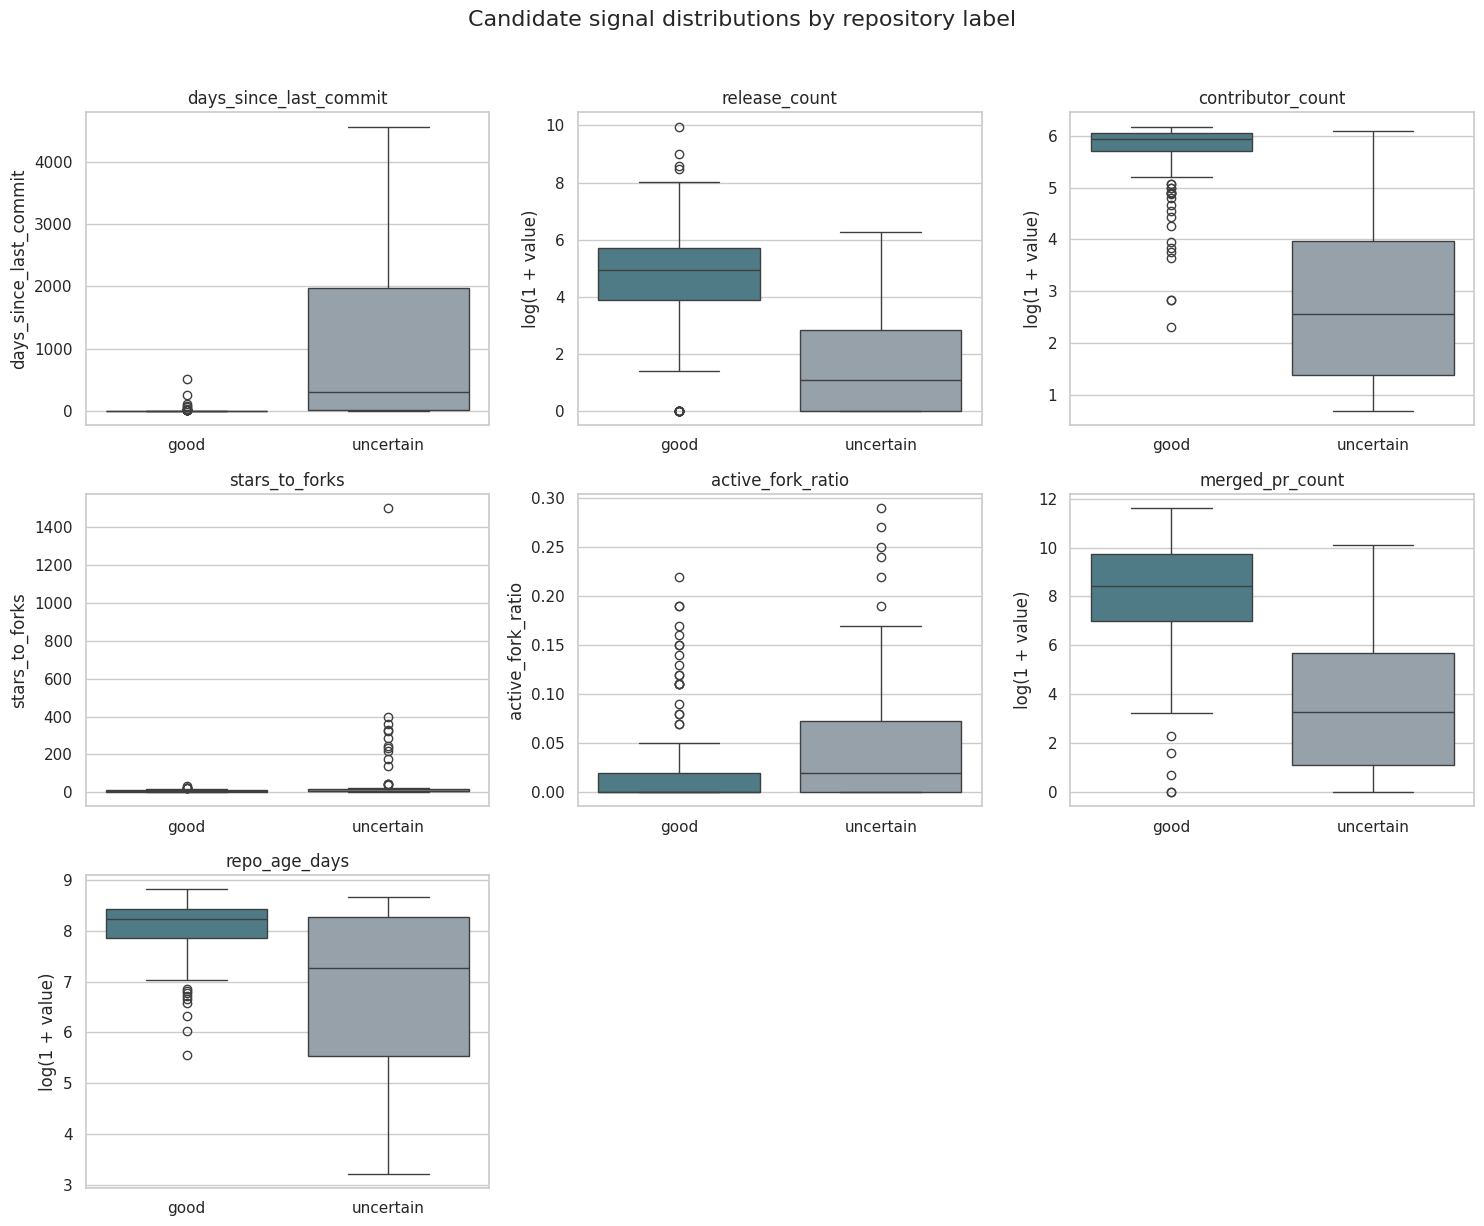

In [6]:
plot_features = [
    "days_since_last_commit", "release_count", "contributor_count",
    "stars_to_forks", "active_fork_ratio", "merged_pr_count", "repo_age_days"
]

fig, axes = plt.subplots(3, 3, figsize=(15, 12))
axes = axes.ravel()
for ax, column in zip(axes, plot_features):
    plot_df = df[["label", column]].dropna().copy()
    if column in {"release_count", "contributor_count", "merged_pr_count", "repo_age_days"}:
        plot_df[column] = np.log1p(plot_df[column].clip(lower=0))
        ylabel = "log(1 + value)"
    else:
        ylabel = column
    sns.boxplot(data=plot_df, x="label", y=column, order=["good", "uncertain"], ax=ax, palette={"good":"#45818e", "uncertain":"#93a1ad"}, hue="label", legend=False)
    ax.set_title(column)
    ax.set_ylabel(ylabel)
    ax.set_xlabel("")
for ax in axes[len(plot_features):]:
    ax.axis("off")
plt.suptitle("Candidate signal distributions by repository label", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()


### Figure takeaway

The known-good repositories show stronger development activity. Their median contributor count is **381 versus 12** for uncertain repositories, and their median merged pull-request count is **4,565.5 versus 26**. The median time since the last commit is **0 days for good repositories versus 304.5 days for uncertain repositories**, suggesting that ongoing maintenance and external participation may be more informative than popularity alone.

## 7. Feature relationships

Correlation helps identify redundant signals. Highly correlated features may represent similar underlying behavior and should be interpreted carefully in the final model.


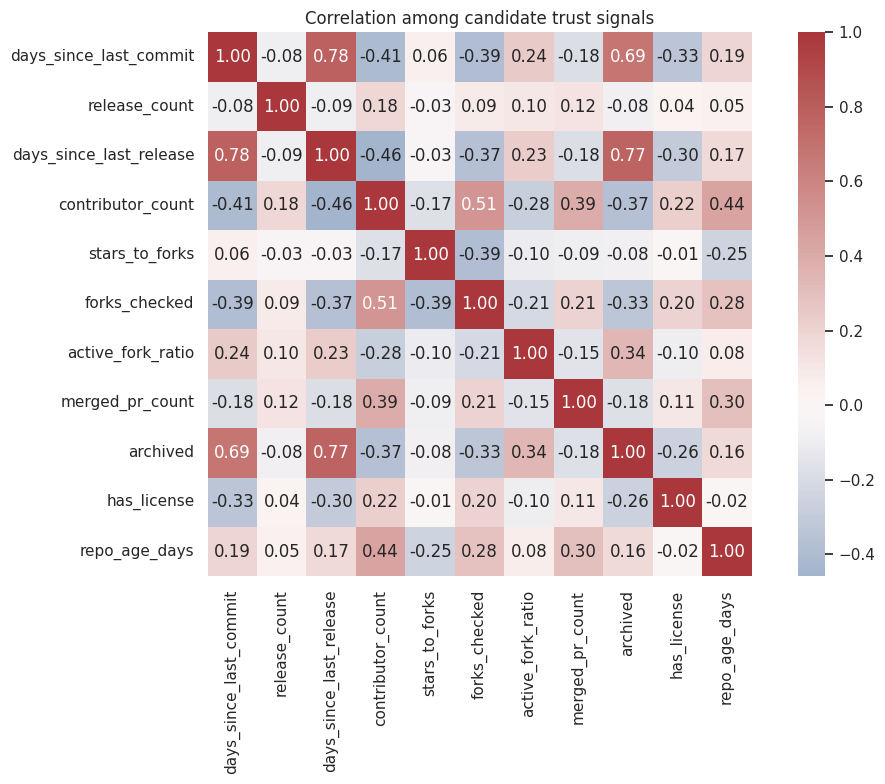

In [7]:
corr = df[numeric_features].corr()
plt.figure(figsize=(11, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", center=0, square=True)
plt.title("Correlation among candidate trust signals")
plt.tight_layout()
plt.show()


### Figure takeaway

The correlation heatmap helps identify signals that may be measuring similar underlying behavior. If two features are highly correlated, the final logistic regression should be interpreted carefully because their coefficients may overlap. This is one reason to examine both individual signals and the combined model.

## 8. Preliminary individual-signal AUC

For each numeric signal, AUC measures how well that signal alone separates the Good and Uncertain labels. This is not the final model AUC. Signals with missing values are evaluated only on rows where the signal is available.


,feature,rows_used,auc,auc_direction_free
3,contributor_count,239,0.931,0.931
7,merged_pr_count,235,0.903,0.903
0,days_since_last_commit,240,0.101,0.899
1,release_count,240,0.848,0.848
2,days_since_last_release,179,0.186,0.814
5,forks_checked,240,0.735,0.735
10,repo_age_days,240,0.729,0.729
8,archived,240,0.296,0.704
6,active_fork_ratio,234,0.368,0.632
4,stars_to_forks,233,0.432,0.568


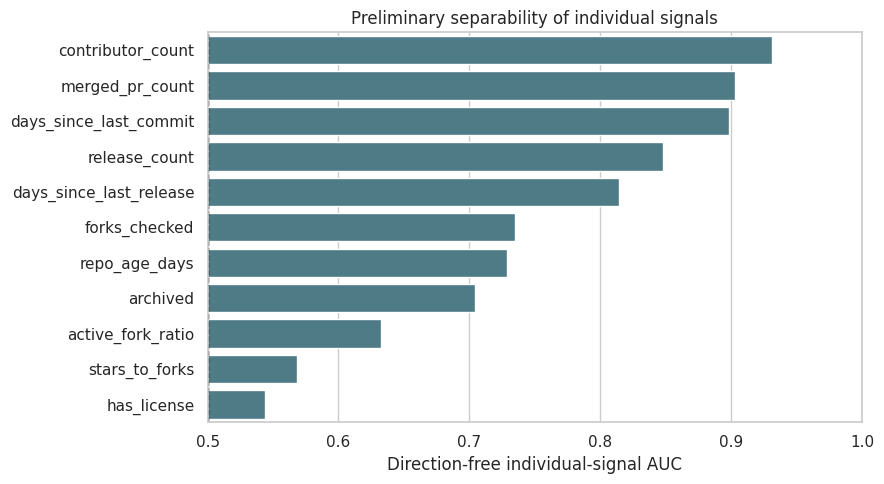

In [8]:
auc_rows = []
valid = df[df["label"].isin(["good", "uncertain"])].copy()
valid["y_good"] = (valid["label"] == "good").astype(int)

for column in numeric_features:
    subset = valid[[column, "y_good"]].dropna()
    if subset["y_good"].nunique() < 2 or len(subset) < 10:
        auc_rows.append({"feature": column, "rows_used": len(subset), "auc": np.nan})
        continue
    raw_auc = roc_auc_score(subset["y_good"], subset[column])
    auc_rows.append({"feature": column, "rows_used": len(subset), "auc": raw_auc, "auc_direction_free": max(raw_auc, 1 - raw_auc)})

auc_table = pd.DataFrame(auc_rows).sort_values("auc_direction_free", ascending=False)
display(auc_table.round(3))

plt.figure(figsize=(9, 5))
sns.barplot(data=auc_table, y="feature", x="auc_direction_free", color="#45818e")
plt.axvline(0.5, color="black", linestyle="--", linewidth=1)
plt.xlim(0.5, 1.0)
plt.xlabel("Direction-free individual-signal AUC")
plt.ylabel("")
plt.title("Preliminary separability of individual signals")
plt.tight_layout()
plt.show()


### Figure takeaway

The strongest individual signals were **contributor count (AUC = 0.931)**, **merged pull requests (AUC = 0.903)**, and **days since last commit (direction-free AUC = 0.899)**. Release count also performed well at **AUC = 0.848**. In contrast, `has_license` had an AUC of only **0.544**, close to random performance. This supports focusing on harder-to-fake community and maintenance activity instead of simple checklist features.

## 9. EDA takeaways

- The final dataset combines repository labels and GitHub-derived features using `repo` as the key.
- Repository activity is unevenly distributed, so count features should be interpreted on a suitable scale.
- Missing values must be handled explicitly, especially for release and fork-related signals.
- Individual AUC shows which signals may be useful, but the final logistic-regression model should evaluate combinations of signals.
- Repository age should be analyzed as a potential confounder and compared with and without age in the final model.
- Stars and popularity should not be treated as sufficient evidence of trust.
- Uncertain repositories should remain a comparison or evaluation group rather than being described as malicious.


### Overall interpretation

The exploratory results suggest that trust is better represented by a combination of maintenance and community signals—including contributors, merged pull requests, releases, and recent activity—than by popularity alone. These are preliminary individual-signal results, not the final model performance. The next step is to fit and evaluate one consolidated logistic regression model and convert its interpretable output into a 0–100 score with feature explanations.

## 10. Limitations and next steps

- The labels are supplied comparison labels and may not capture every dimension of repository quality.
- Public GitHub activity is an imperfect proxy for trust and can favor older or more visible projects.
- The dataset is relatively small, so AUC estimates may be unstable.
- Future work should evaluate pull-request history, external contributors, fork contributions, contributor history, star-growth patterns, and releases.
- The next notebook should fit and evaluate the logistic-regression model using a documented train/test split and an unseen holdout set.
